# 01 · MLP em NumPy: análise

Pré-requisito: ter rodado os três treinos da Fase 1.

```bash
python -m src.numpy_nn.train --config configs/numpy_mlp.yaml --evaluate-test
python -m src.numpy_nn.train --config configs/numpy_mlp_sgd.yaml
python -m src.numpy_nn.train --config configs/numpy_mlp_momentum.yaml
```

In [1]:
import sys
sys.path.append("..")
import os
os.chdir("..")  # roda a partir da raiz do projeto, como os scripts

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import CLASS_NAMES, load_fashion_mnist
from src.numpy_nn.model import build_mlp
from src.utils.config import load_config
from src.utils.metrics import accuracy, confusion_matrix

ds = load_fashion_mnist()

## 1. Curvas de treino do modelo principal (Adam)

melhor época: 23 | val 89.68% | treino 93.71%
diferença treino - validação na última época: 5.1 p.p.


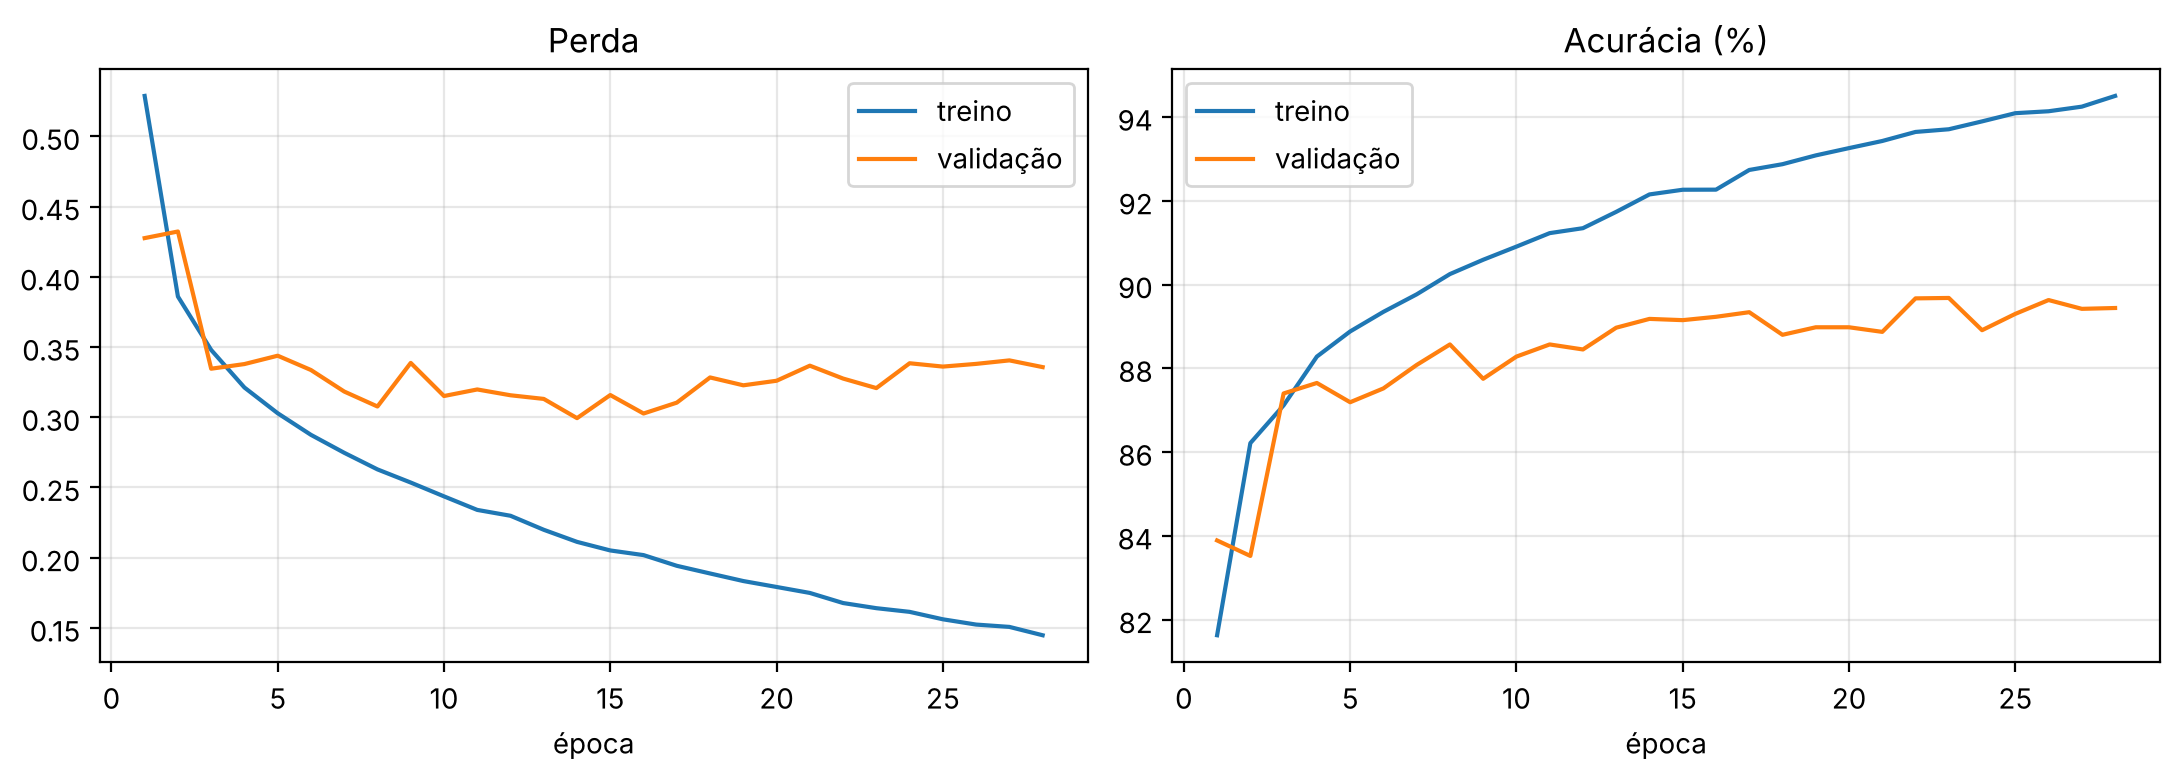

In [2]:
m = pd.read_csv("results/numpy_mlp/metrics.csv")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(m.epoch, m.train_loss, label="treino"); a1.plot(m.epoch, m.val_loss, label="validação")
a1.set(title="Perda", xlabel="época"); a1.legend(); a1.grid(alpha=.3)
a2.plot(m.epoch, 100 * m.train_acc, label="treino"); a2.plot(m.epoch, 100 * m.val_acc, label="validação")
a2.set(title="Acurácia (%)", xlabel="época"); a2.legend(); a2.grid(alpha=.3)
plt.tight_layout()
best = m.loc[m.val_acc.idxmax()]
print(f"melhor época: {int(best.epoch)} | val {100*best.val_acc:.2f}% | treino {100*best.train_acc:.2f}%")
print(f"diferença treino - validação na última época: {100*(m.train_acc.iloc[-1]-m.val_acc.iloc[-1]):.1f} p.p.")

A distância crescente entre as curvas de treino e validação é **overfitting**: a rede passa a decorar o treino. O early stopping guarda os pesos da melhor época de validação, por isso o modelo final não é o da última época.

## 2. SGD x Momentum x Adam

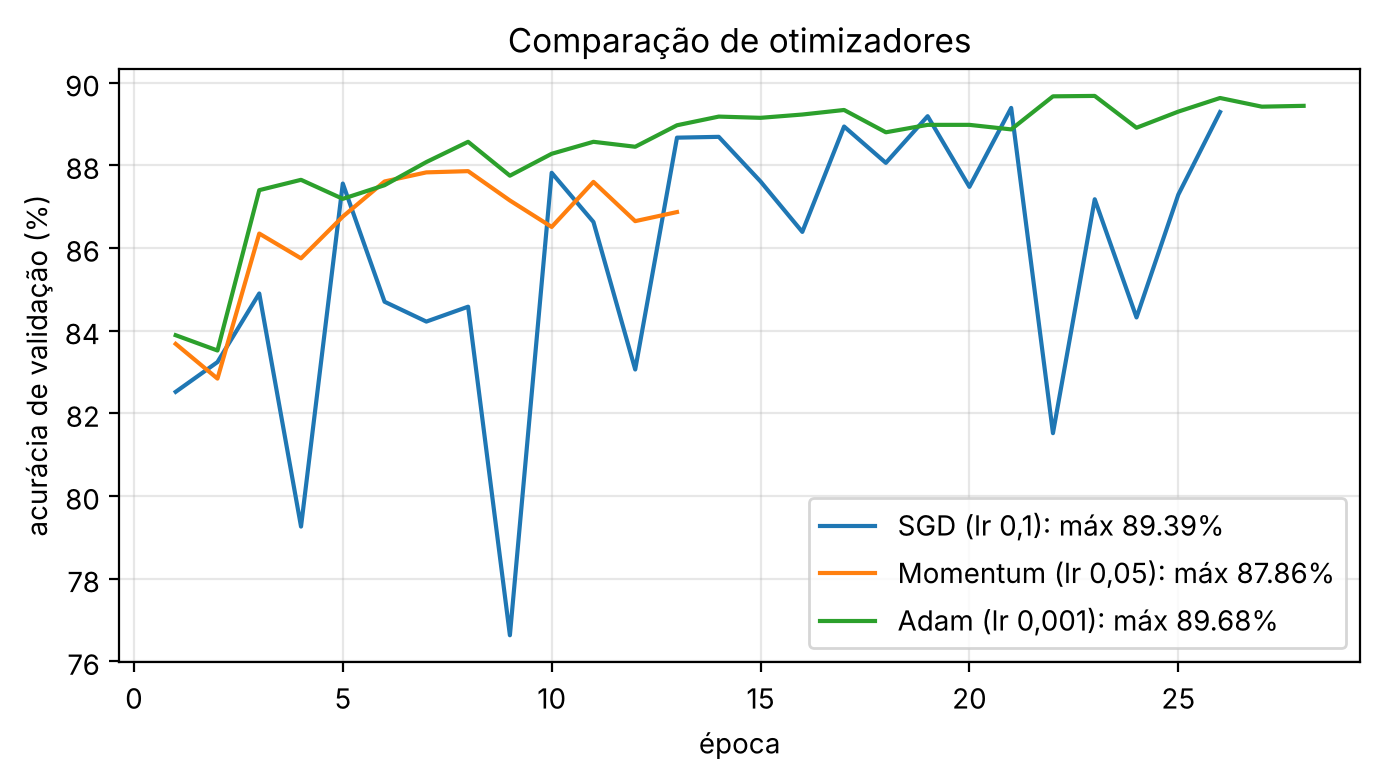

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, path in [("SGD (lr 0,1)", "numpy_mlp_sgd"), ("Momentum (lr 0,05)", "numpy_mlp_momentum"), ("Adam (lr 0,001)", "numpy_mlp")]:
    d = pd.read_csv(f"results/{path}/metrics.csv")
    ax.plot(d.epoch, 100 * d.val_acc, label=f"{name}: máx {100*d.val_acc.max():.2f}%")
ax.set(xlabel="época", ylabel="acurácia de validação (%)", title="Comparação de otimizadores")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig("results/numpy_otimizadores.png", dpi=150)

Pontos para observar: qual converge mais rápido nas primeiras épocas, qual oscila mais e qual atinge o melhor pico. As taxas de aprendizado não foram otimizadas para cada otimizador, então a comparação é indicativa, não definitiva.

## 3. Matriz de confusão (validação)

acurácia de validação: 89.68%
       Camisa confundida com Camiseta/top  132 vezes
       Casaco confundida com Pulôver       91 vezes
      Pulôver confundida com Casaco        89 vezes
       Camisa confundida com Pulôver       73 vezes
 Camiseta/top confundida com Camisa        70 vezes


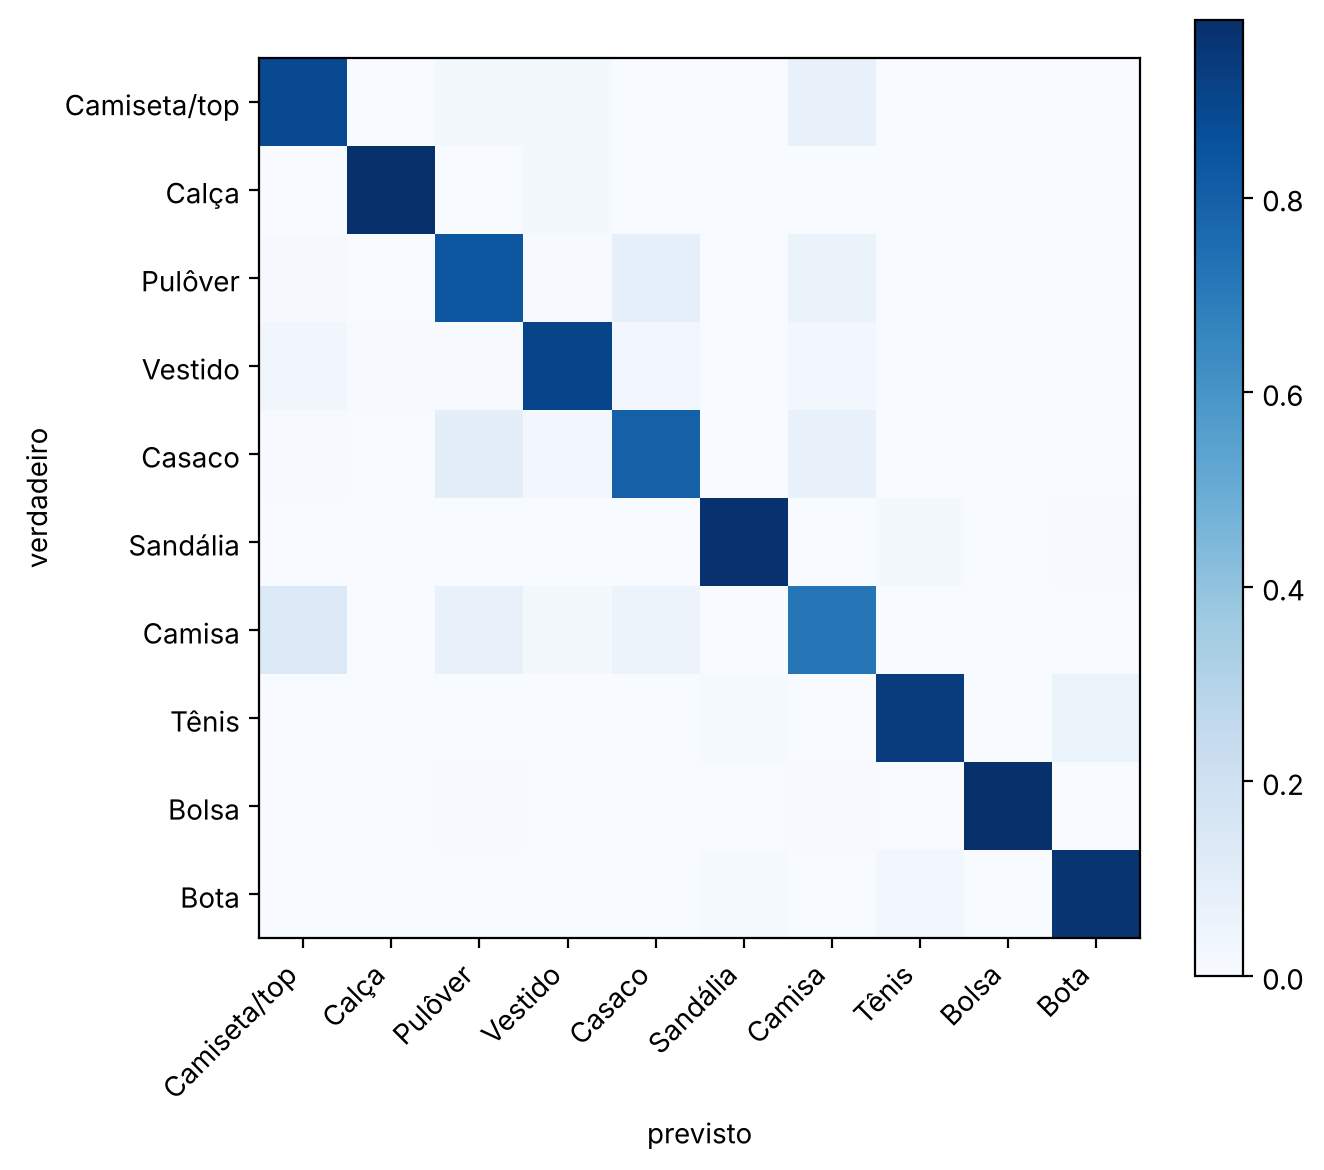

In [4]:
cfg = load_config("configs/numpy_mlp.yaml")
model = build_mlp(784, cfg["model"]["hidden"], 10, cfg["model"]["activation"], 0.0, cfg["model"]["init"])
model.load("checkpoints/numpy_mlp.npz")
pred = model.predict(ds.X_val)
cm = confusion_matrix(ds.y_val, pred)
print(f"acurácia de validação: {100*accuracy(ds.y_val, pred):.2f}%")
off = cm.copy(); np.fill_diagonal(off, 0)
for k in np.argsort(off.ravel())[::-1][:5]:
    i, j = divmod(k, 10)
    print(f"{CLASS_NAMES[i]:>13} confundida com {CLASS_NAMES[j]:<13} {off[i, j]} vezes")
plt.figure(figsize=(7, 6))
plt.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues")
plt.xticks(range(10), CLASS_NAMES, rotation=45, ha="right"); plt.yticks(range(10), CLASS_NAMES)
plt.xlabel("previsto"); plt.ylabel("verdadeiro"); plt.colorbar(); plt.tight_layout()

## 4. Erros mais confiantes

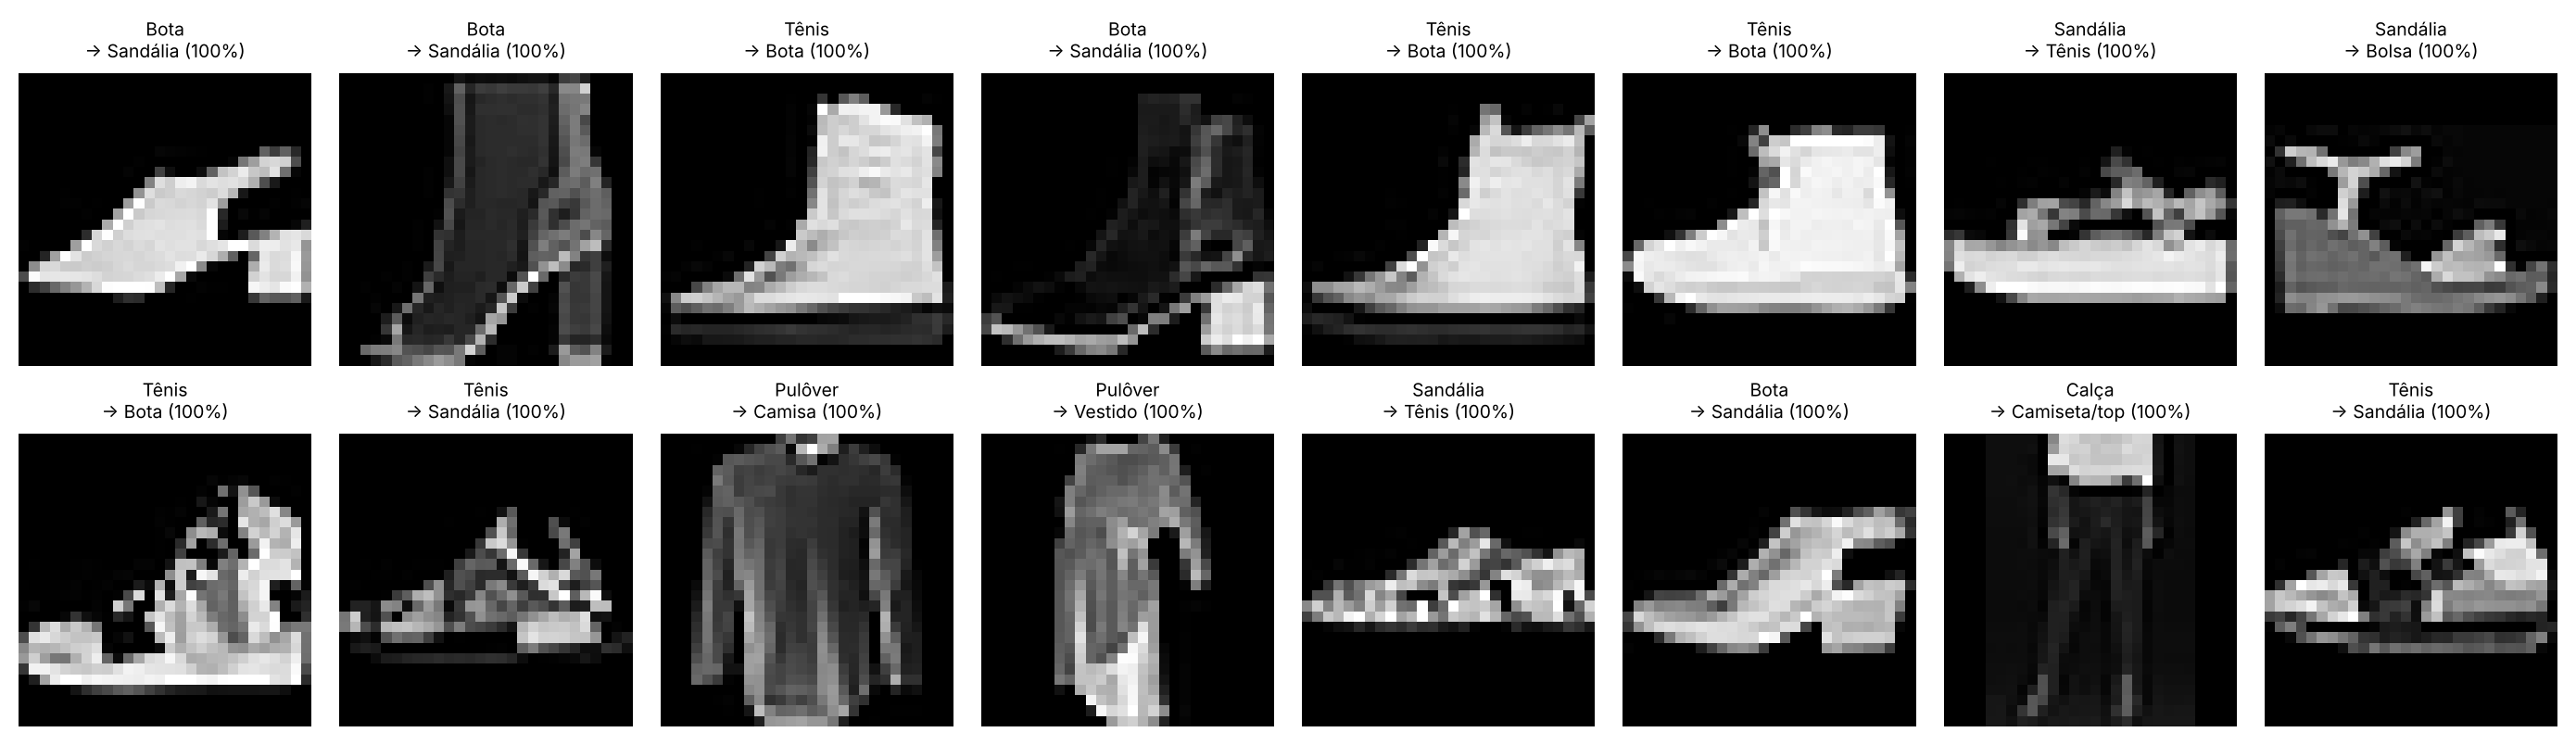

In [5]:
from src.numpy_nn.losses import softmax
model.eval()
probs = softmax(model.forward(ds.X_val))
wrong = np.where(probs.argmax(1) != ds.y_val)[0]
top = wrong[np.argsort(-probs[wrong].max(1))][:16]
fig, axes = plt.subplots(2, 8, figsize=(14, 4.2))
for ax, i in zip(axes.ravel(), top):
    ax.imshow(ds.X_val[i].reshape(28, 28), cmap="gray"); ax.axis("off")
    ax.set_title(f"{CLASS_NAMES[ds.y_val[i]]}\n→ {CLASS_NAMES[probs[i].argmax()]} ({probs[i].max():.0%})", fontsize=7)
plt.tight_layout()

Vários desses "erros" são imagens ambíguas até para pessoas, ou rótulos discutíveis no próprio dataset.

## 5. Saúde da rede: ativações por camada

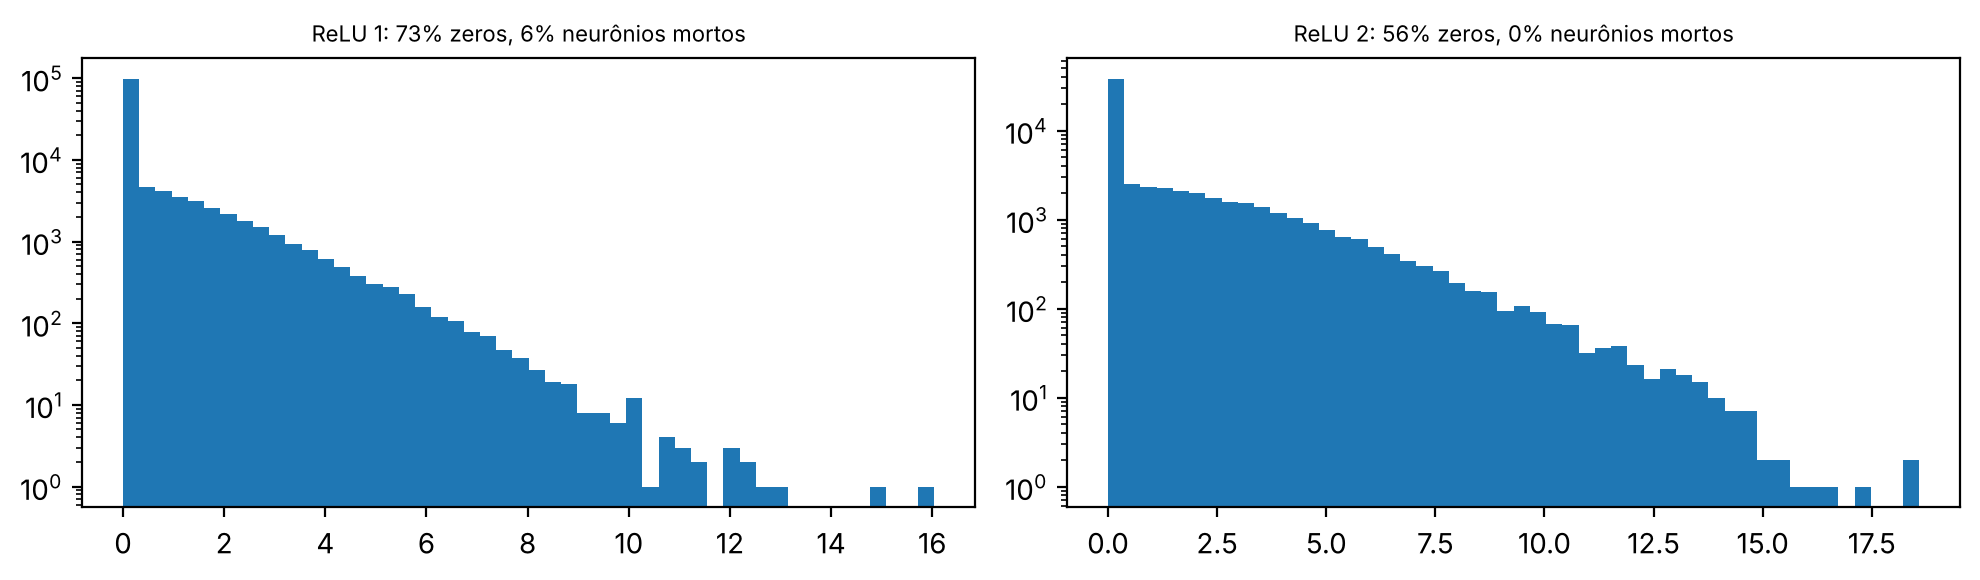

In [6]:
from src.numpy_nn.activations import ReLU
x = ds.X_val[:1000]
acts = []
for layer in model.layers:
    x = layer.forward(x)
    if isinstance(layer, ReLU):
        acts.append(x)
fig, axes = plt.subplots(1, len(acts), figsize=(10, 3))
for k, (ax, a) in enumerate(zip(axes, acts)):
    dead = np.mean(a.max(0) == 0)
    ax.hist(a.ravel(), bins=50, log=True)
    ax.set_title(f"ReLU {k+1}: {100*np.mean(a == 0):.0f}% zeros, {100*dead:.0f}% neurônios mortos", fontsize=8)
plt.tight_layout()

Um neurônio **morto** fica zerado para todos os 1.000 exemplos e nunca mais recebe gradiente. Uma fração pequena é normal; uma fração grande indicaria problema de inicialização ou taxa de aprendizado alta demais.